# 01 · Mengenal data mentah PIHPS

**Tujuan notebook ini:** memahami struktur dan kualitas data harga PIHPS sebelum cleaning, lalu memutuskan
preprocessing apa yang dibutuhkan **berdasarkan tujuan analisis** (Q1–Q6 di brief proyek), bukan berdasarkan kebiasaan.

| Kode | Pertanyaan analisis | Data yang paling dibutuhkan |
|---|---|---|
| Q1 | Komoditas & kota mana yang harganya paling bergejolak? | perubahan harga minggu ke minggu |
| Q2 | Rute antar kota mana yang masih untung setelah ongkos angkut? | level harga sumber vs tujuan |
| Q3 | Kota mana yang harganya naik lebih dulu? | perubahan harga mingguan antar kota |
| Q4 | Berapa minggu sebelum Idul Fitri harga mulai naik? | harga mingguan di sekitar Idul Fitri |
| Q5 | Berapa tambahan harga dari produsen → pedagang besar → pasar? | level harga 3 tingkat di kota yang sama |
| Q6 | Apakah peringatan dini sederhana akurat? | seri mingguan yang bersih & panjang |

**Data:** hasil Tahap 1 (`src/acquire.py`): 960 file JSON, 3 Juli 2023 – 23 Oktober 2026, 6 provinsi Pulau Jawa,
4 jenis pasar × 6 komoditas. Tidak ada cleaning di notebook ini. Semua angka dihitung dari data mentah.

**Reproduksi:** data mentah tidak disimpan di repo. Jalankan dari root proyek:
```
python -m src.acquire
```
lalu jalankan ulang notebook ini. Ambang batas yang dipakai dibaca dari `config/config.yaml` (bagian `cleaning`).

### Ringkasan temuan
1. **Format rapi, struktur perlu dirapikan.** Semua 665 ribu harga terbaca. Baris nasional = rata-rata nasional resmi,
   tetapi baris kota tidak membawa provinsi dan ada satu kota bernama ganda (Surakarta).
2. **Hari libur diisi harga hari sebelumnya**, termasuk seminggu penuh sekitar Idul Fitri.
3. **Harga di luar pasar tradisional jarang berubah** (produsen ~96% hari tidak berubah).
4. **Ada salah input**: lonjakan sehari dan pergeseran level yang bertahan.
5. Data **cukup** untuk gejolak, rute, dan kota penentu arah; **terbatas** untuk pola Idul Fitri, peringatan dini,
   dan tambahan harga rantai pasok.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import yaml

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
from src.load_raw import JENIS_PASAR, load_raw_long, load_regency_ref

RAW = ROOT / "data" / "raw"
cfg = yaml.safe_load((ROOT / "config" / "config.yaml").read_text(encoding="utf-8"))
C = cfg["cleaning"]

KOMODITAS = {  # urutan tetap dipakai di semua tabel & grafik
    "com_16": "Cabai Rawit Merah", "com_14": "Cabai Merah Keriting", "com_11": "Bawang Merah",
    "com_12": "Bawang Putih", "com_7": "Daging Ayam Ras", "com_10": "Telur Ayam Ras",
}
PASAR = ["Pasar Tradisional", "Pasar Modern", "Pedagang Besar", "Produsen"]

# Warna (aturan brief §6.4): teal = utama, biru = turun/murah, oranye = naik/peringatan; abu = konteks
TEAL, BLUE, ORANGE, GRAY = "#1baf7a", "#2a78d6", "#eb6834", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "figure.dpi": 110, "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df = load_raw_long(RAW)
df["komoditas"] = pd.Categorical(df.komoditas_id.map(KOMODITAS), categories=list(KOMODITAS.values()), ordered=True)
df["jenis_pasar"] = pd.Categorical(df.jenis_pasar_id.map(JENIS_PASAR), categories=PASAR, ordered=True)
kota = df[df.level == 2].copy()
SERI = ["jenis_pasar", "komoditas", "nama"]
kota = kota.sort_values(SERI + ["tanggal"]).reset_index(drop=True)
print(f"{len(df):,} baris | {df.harga.notna().sum():,} harga terisi | {df.kosong.sum():,} kosong")
df.head()

673,596 baris | 665,084 harga terisi | 8,512 kosong


,jenis_pasar_id,komoditas_id,level,provinsi,nama,tanggal,harga,kosong,komoditas,jenis_pasar
0,1,com_10,0,NaN,Semua Provinsi,2023-07-03,31750.0,False,Telur Ayam Ras,Pasar Tradisional
1,1,com_10,0,NaN,Semua Provinsi,2023-07-04,31750.0,False,Telur Ayam Ras,Pasar Tradisional
2,1,com_10,0,NaN,Semua Provinsi,2023-07-05,31750.0,False,Telur Ayam Ras,Pasar Tradisional
3,1,com_10,0,NaN,Semua Provinsi,2023-07-06,31750.0,False,Telur Ayam Ras,Pasar Tradisional
4,1,com_10,0,NaN,Semua Provinsi,2023-07-07,31750.0,False,Telur Ayam Ras,Pasar Tradisional


## 1. Struktur data

Respons API berformat **lebar**: satu baris per wilayah, satu kolom per tanggal. `load_raw_long` mengubahnya menjadi
format panjang. Yang perlu dipastikan sebelum cleaning:
- arti baris `level` 0/1/2 (nasional, provinsi, kota),
- format angka & tanggal,
- konsistensi nama kota (karena baris tidak membawa id).

In [2]:
print("Baris per level:", df.groupby("level").size().rename({0: "nasional", 1: "provinsi", 2: "kota"}).to_dict())
terisi = df.harga.dropna()
print("Semua harga bilangan bulat Rupiah:", bool((terisi % 1 == 0).all()), "| harga <= 0:", int((terisi <= 0).sum()))

tgl = pd.DatetimeIndex(sorted(df.tanggal.unique()))
hari_kerja = pd.bdate_range(tgl.min(), tgl.max())
print(f"Rentang {tgl.min():%Y-%m-%d} s/d {tgl.max():%Y-%m-%d}: {len(tgl)} tanggal unik")
print("Tanggal per hari (0=Senin):", pd.Series(tgl.day_of_week).value_counts().sort_index().to_dict())
print("Hari Senin-Jumat yang tidak ada di data:", len(hari_kerja.difference(tgl)))

kota.groupby("jenis_pasar", observed=True).agg(kota_kab=("nama", "nunique")).T

Baris per level: {'nasional': 20760, 'provinsi': 115045, 'kota': 537791}
Semua harga bilangan bulat Rupiah: True | harga <= 0: 0
Rentang 2023-07-03 s/d 2026-10-23: 865 tanggal unik
Tanggal per hari (0=Senin): {0: 173, 1: 173, 2: 173, 3: 173, 4: 173}
Hari Senin-Jumat yang tidak ada di data: 0


jenis_pasar,Pasar Tradisional,Pasar Modern,Pedagang Besar,Produsen
kota_kab,35,24,23,48


**Arti baris nasional.** Data diunduh dengan filter 6 provinsi Jawa, tetapi baris `level 0` ("Semua Provinsi")
nilainya jauh di atas semua provinsi Jawa. Untuk memastikan, baris ini dibandingkan dengan satu permintaan nasional
**tanpa** filter provinsi (cabai rawit, pasar tradisional, Maret 2024; disimpan di `data/raw/check/`).

In [3]:
cek = json.loads((RAW / "check" / "nasional_pt1_com_16_2024-03.json").read_text(encoding="utf-8"))["data"]
lv0 = next(r for r in cek if r["level"] == 0)
nasional_resmi = pd.Series({pd.to_datetime(k, format="%d/%m/%Y"): float(v.replace(",", ""))
                            for k, v in lv0.items() if "/" in k})
milik_kita = (df[(df.level == 0) & (df.jenis_pasar_id == 1) & (df.komoditas_id == "com_16")]
              .set_index("tanggal").harga.loc["2024-03"])
print("Baris level 0 di data kita = rata-rata nasional resmi:", bool(milik_kita.equals(nasional_resmi.loc[milik_kita.index])))

# Provinsi = rata-rata kota?
sub = df[(df.jenis_pasar_id == 1) & df.harga.notna()]
prov = sub[sub.level == 1].set_index(["komoditas_id", "provinsi", "tanggal"]).harga
rata_kota = sub[sub.level == 2].groupby(["komoditas_id", "provinsi", "tanggal"]).harga.mean()
selisih = ((prov - rata_kota) / rata_kota * 100).abs().dropna()
print(f"Provinsi vs rata-rata kotanya: selisih median {selisih.median():.2f}%, maksimum {selisih.max():.2f}%")

Baris level 0 di data kita = rata-rata nasional resmi: True
Provinsi vs rata-rata kotanya: selisih median 0.01%, maksimum 0.14%


**Nama kota.** Baris kota hanya membawa nama, jadi nama harus dipetakan ke id lewat tabel referensi
(`data/raw/ref/regency_*.json`).

In [4]:
ref = load_regency_ref(RAW)
pasangan_data = set(zip(kota.jenis_pasar_id, kota.nama))
pasangan_ref = set(zip(ref.jenis_pasar_id, ref.nama))
print("Nama kota di data yang tidak ada di referensi:", len(pasangan_data - pasangan_ref))

nama_mentah = [r["name"] for f in (RAW / "ref").glob("regency_*.json")
               for r in json.loads(f.read_text(encoding="utf-8"))["data"]]
print("Nama dengan spasi di ujung:", sorted({n.strip() for n in nama_mentah if n != n.strip()}))
print("id dengan lebih dari 1 nama:", int((ref.groupby("kota_id").nama.nunique() > 1).sum()))
ref[ref.nama.str.contains("Surakarta")].drop_duplicates(["kota_id", "nama", "jenis_pasar_id"])

Nama kota di data yang tidak ada di referensi: 0
Nama dengan spasi di ujung: ['Kab. Blora', 'Kab. Boyolali', 'Kab. Jombang', 'Kab. Lamongan', 'Kab. Pati', 'Kab. Sidoarjo', 'Kab. Subang']
id dengan lebih dari 1 nama: 0


,jenis_pasar_id,provinsi_id,kota_id,nama
22,1,14,36,Kota Surakarta (Solo)
47,2,14,787,Kota Surakarta
49,2,14,36,Kota Surakarta (Solo)
72,3,14,36,Kota Surakarta (Solo)
118,4,14,36,Kota Surakarta (Solo)


In [5]:
solo = (kota[(kota.jenis_pasar_id == 2) & kota.nama.str.contains("Surakarta")]
        .pivot_table(index=["komoditas", "tanggal"], columns="nama", values="harga", observed=True))
print(f"Pasar modern: dua seri Surakarta identik pada {(solo.iloc[:, 0] == solo.iloc[:, 1]).mean():.0%} hari, "
      f"korelasi {solo.corr().iloc[0, 1]:.3f}")

Pasar modern: dua seri Surakarta identik pada 87% hari, korelasi 0.995


> **Temuan:** Formatnya rapi (semua harga bilangan bulat, tidak ada hari kerja yang hilang). Rata-rata nasional sudah
> tersedia di setiap file sebagai pembanding. Yang perlu dirapikan: provinsi tiap kota, spasi di ujung nama,
> dan **Surakarta di pasar modern yang tercatat dua kali** (id 787 dan id 36) dengan harga hampir sama.

## 2. Hari libur diisi harga hari sebelumnya

Semua hari Senin–Jumat ada di data, **termasuk hari libur nasional**, padahal FAQ PIHPS menyebut pencacahan hanya
pada hari kerja. Dugaan: pada hari libur BI mengisi harga hari kerja terakhir. Cara mengujinya: hitung, per tanggal,
berapa persen seri pasar tradisional yang harganya **sama persis** dengan hari sebelumnya.

Hari biasa: rata-rata 56% seri tidak berubah dari hari sebelumnya
Hari dengan > 90% seri tidak berubah: 72


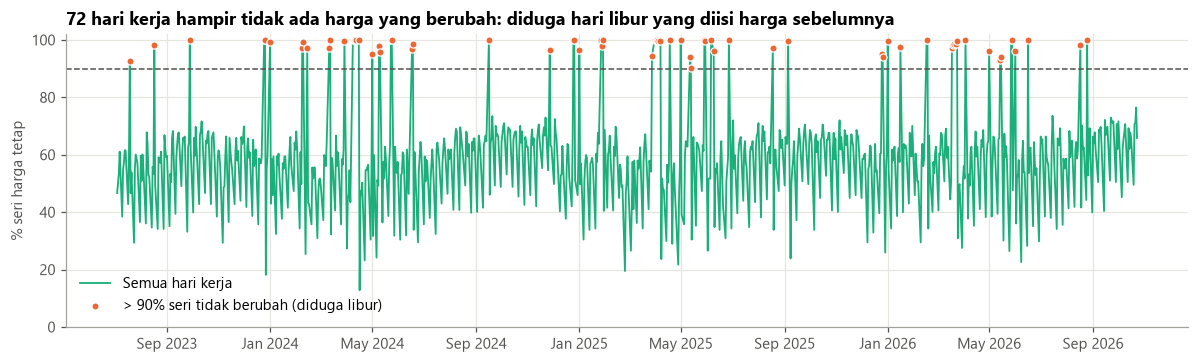

In [6]:
trad = kota[kota.jenis_pasar_id == 1].copy()
trad["selisih_harian"] = trad.groupby(SERI, observed=True).harga.diff()
porsi_sama = (trad.dropna(subset=["selisih_harian"]).groupby("tanggal").selisih_harian
              .apply(lambda s: (s == 0).mean()))
ambang = C["libur_ambang_tidak_berubah"]
libur = porsi_sama[porsi_sama > ambang]
print(f"Hari biasa: rata-rata {porsi_sama[porsi_sama <= ambang].mean():.0%} seri tidak berubah dari hari sebelumnya")
print(f"Hari dengan > {ambang:.0%} seri tidak berubah: {len(libur)}")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(porsi_sama.index, porsi_sama.values * 100, color=TEAL, lw=1.2, label="Semua hari kerja")
ax.scatter(libur.index, libur.values * 100, s=22, color=ORANGE, zorder=3, edgecolor="white", lw=0.8,
           label=f"> {ambang:.0%} seri tidak berubah (diduga libur)")
ax.axhline(ambang * 100, color=INK2, lw=1, ls="--")
ax.set_ylim(0, 102); ax.set_ylabel("% seri harga tetap")
ax.set_title(f"{len(libur)} hari kerja hampir tidak ada harga yang berubah: diduga hari libur yang diisi harga sebelumnya")
ax.legend(frameon=False, loc="lower left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

In [7]:
# Kelompokkan hari "libur" yang berurutan (hari kerja berturut-turut) menjadi satu periode
hk = pd.Series(range(len(tgl)), index=tgl)
urut = hk.loc[libur.index]
periode = (pd.DataFrame({"tanggal": libur.index, "grp": (urut.diff() != 1).cumsum().values})
           .groupby("grp").tanggal.agg(mulai="min", selesai="max", hari_kerja="count"))
periode.sort_values("hari_kerja", ascending=False).head(8)

,mulai,selesai,hari_kerja
grp,,,
20,2025-03-28,2025-04-07,7
10,2024-04-08,2024-04-15,6
33,2026-03-18,2026-03-24,5
19,2025-01-27,2025-01-29,3
17,2024-12-25,2024-12-26,2
8,2024-03-11,2024-03-12,2
6,2024-02-08,2024-02-09,2
24,2025-05-29,2025-05-30,2


Periode terpanjang jatuh tepat di sekitar Idul Fitri (Lebaran 2024, 2025, 2026). Contoh di bawah: cabai rawit di dua
kota tujuan pada Lebaran 2025. Harga berhenti bergerak selama seminggu, lalu "melompat" begitu pencacahan dimulai lagi.

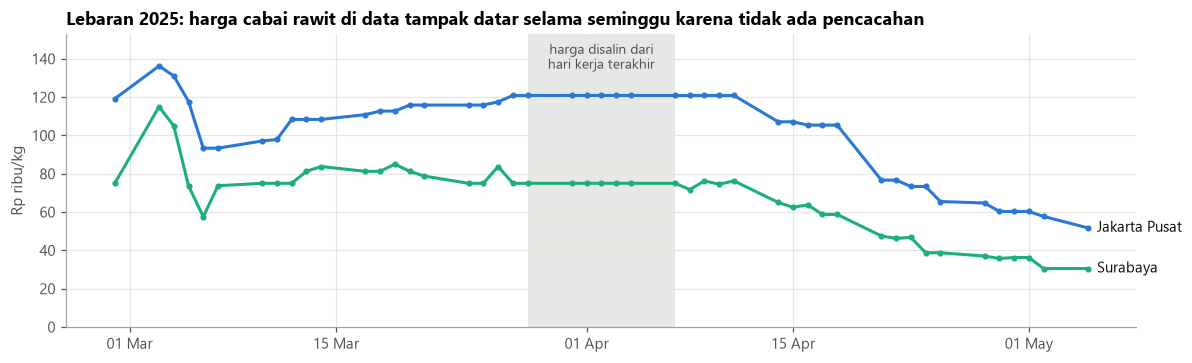

In [8]:
lebaran = periode.sort_values("hari_kerja", ascending=False).iloc[:3].sort_values("mulai")
p = lebaran[lebaran.mulai.dt.year == 2025].iloc[0]
jendela = trad[(trad.komoditas == "Cabai Rawit Merah") & trad.nama.isin(["Kota Jakarta Pusat", "Kota Surabaya"])
               & trad.tanggal.between(p.mulai - pd.Timedelta(days=28), p.selesai + pd.Timedelta(days=28))]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axvspan(p.mulai, p.selesai, color=GRAY, alpha=0.25, lw=0)
for nama, warna in [("Kota Jakarta Pusat", BLUE), ("Kota Surabaya", TEAL)]:
    s = jendela[jendela.nama == nama]
    ax.plot(s.tanggal, s.harga / 1000, color=warna, lw=2, marker="o", ms=3)
    ax.annotate(nama.replace("Kota ", ""), (s.tanggal.iloc[-1], s.harga.iloc[-1] / 1000), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
ax.text(p.mulai + (p.selesai - p.mulai) / 2, ax.get_ylim()[1] * 0.97, "harga disalin dari\nhari kerja terakhir",
        ha="center", va="top", color=INK2, fontsize=9)
ax.set_ylabel("Rp ribu/kg")
ax.set_title("Lebaran 2025: harga cabai rawit di data tampak datar selama seminggu karena tidak ada pencacahan")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

> **Temuan:** Ada beberapa puluh hari libur dan cuti bersama yang harganya hanya disalin dari hari sebelumnya, termasuk
> **seminggu penuh setiap Lebaran**. Kalau dibiarkan, harga di minggu Lebaran tampak tenang padahal tidak dicatat,
> dan gejolak harga terlihat lebih kecil dari kenyataan. Tindakan: tandai hari-hari ini dan anggap kosong.

## 3. Data kosong

Brief membedakan dua jenis kosong: **komoditas tidak dijual di kota itu** (seluruh seri kosong → buang) dan
**celah sementara** (≤ 5 hari kerja → isi dengan harga terakhir; lebih panjang → biarkan kosong).
Hitungan di bawah hanya memakai baris kota.

In [9]:
(kota.pivot_table(index="komoditas", columns="jenis_pasar", values="kosong", aggfunc="mean", observed=True)
 .mul(100).round(2).style.format("{:.2f}%", na_rep="–").set_caption("% sel kosong"))

jenis_pasar,Pasar Tradisional,Pasar Modern,Pedagang Besar,Produsen
komoditas,,,,
Cabai Rawit Merah,0.94%,3.32%,0.29%,0.97%
Cabai Merah Keriting,1.01%,3.19%,0.32%,1.37%
Bawang Merah,0.94%,4.11%,0.29%,1.71%
Bawang Putih,0.94%,3.82%,0.29%,–
Daging Ayam Ras,0.94%,3.03%,0.29%,1.08%
Telur Ayam Ras,0.94%,2.89%,0.27%,0.93%


In [10]:
def panjang_celah(mask: np.ndarray) -> list[int]:
    # panjang setiap rangkaian True berturut-turut
    padded = np.concatenate([[False], mask, [False]]).astype(int)
    d = np.diff(padded)
    return list(np.flatnonzero(d == -1) - np.flatnonzero(d == 1))

celah = (kota.groupby(SERI, observed=True).kosong
         .apply(lambda s: panjang_celah(s.to_numpy())).rename("celah").reset_index())
semua = pd.Series([x for l in celah.celah for x in l])
print(f"{len(semua):,} celah; {int((semua > C['gap_ffill_maks_hari']).sum())} celah > {C['gap_ffill_maks_hari']} hari kerja; "
      f"terpanjang {semua.max()} hari kerja")
print("Seri yang seluruhnya kosong:", int(kota.groupby(SERI, observed=True).kosong.all().sum()))
semua.value_counts().sort_index().rename("jumlah celah").rename_axis("panjang (hari kerja)").to_frame().T

4,165 celah; 185 celah > 5 hari kerja; terpanjang 39 hari kerja
Seri yang seluruhnya kosong: 0


panjang (hari kerja),1,2,3,4,5,6,7,8,9,10,14,15,16,17,19,20,21,22,23,24,26,29,39
jumlah celah,3306,389,44,239,2,12,84,1,8,2,6,1,2,2,8,11,15,8,20,2,1,1,1


In [11]:
celah["celah_maks"] = celah.celah.apply(lambda l: max(l) if l else 0)
celah["pct_kosong"] = kota.groupby(SERI, observed=True).kosong.mean().mul(100).values
panjang = celah[celah.celah_maks > C["gap_ffill_maks_hari"]]
print("Seri dengan celah > 5 hari kerja, per jenis pasar:",
      panjang.groupby("jenis_pasar", observed=True).size().to_dict())
panjang.sort_values("pct_kosong", ascending=False).head(10).drop(columns="celah").round(1)

Seri dengan celah > 5 hari kerja, per jenis pasar: {'Pasar Tradisional': 13, 'Pasar Modern': 92, 'Produsen': 26}


,jenis_pasar,komoditas,nama,celah_maks,pct_kosong
256,Pasar Modern,Bawang Merah,Kab. Banyuwangi,29,36.1
280,Pasar Modern,Bawang Putih,Kab. Banyuwangi,39,32.6
209,Pasar Modern,Cabai Rawit Merah,Kab. Banyuwangi,21,19.3
39,Pasar Tradisional,Cabai Merah Keriting,Kab. Jember,23,9.7
257,Pasar Modern,Bawang Merah,Kab. Cilacap,26,9.0
295,Pasar Modern,Bawang Putih,Kota Sukabumi,19,8.8
342,Pasar Modern,Telur Ayam Ras,Kota Sukabumi,19,8.8
318,Pasar Modern,Daging Ayam Ras,Kota Sukabumi,19,8.8
247,Pasar Modern,Cabai Merah Keriting,Kota Sukabumi,19,8.8
224,Pasar Modern,Cabai Rawit Merah,Kota Sukabumi,19,8.8


In [12]:
# Celah serentak di pasar modern: tanggal di mana sebagian besar seri modern kosong
modern = kota[kota.jenis_pasar_id == 2].groupby("tanggal").kosong.mean()
serentak = modern[modern > 0.5]
idx = hk.loc[serentak.index]
(pd.DataFrame({"tanggal": serentak.index, "porsi": serentak.values, "grp": (idx.diff() != 1).cumsum().values})
 .groupby("grp").agg(mulai=("tanggal", "min"), selesai=("tanggal", "max"), hari_kerja=("tanggal", "size"),
                     porsi_seri_kosong_maks=("porsi", "max"))
 .query("hari_kerja >= 3").round({"porsi_seri_kosong_maks": 2}).reset_index(drop=True))

,mulai,selesai,hari_kerja,porsi_seri_kosong_maks
0,2023-11-29,2023-12-07,7,0.7
1,2026-09-30,2026-10-05,4,0.6


> **Temuan:** Data kosong sedikit: sekitar 1% di pasar tradisional, 0,3% di pedagang besar, 1–2% di produsen,
> dan 3–4% di pasar modern. Tidak ada seri yang kosong seluruhnya. Hampir semua celah hanya 1–4 hari, jadi aman diisi.
> Pengecualian yang tidak boleh diisi: pasar modern Kab. Banyuwangi (bawang kosong sepertiga waktu), celah sebulan penuh
> di beberapa kabupaten produsen, dan dua periode ketika lebih dari separuh seri pasar modern kosong bersamaan.

## 4. Harga yang jarang berubah

Gejolak harga (Q1) dan kota penentu arah (Q3) mengandalkan **perubahan** harga. Seri yang harganya jarang diperbarui
akan terlihat "stabil" padahal datanya saja yang tidak bergerak. Diukur dengan:
- % hari harga sama persis dengan hari sebelumnya,
- rangkaian terpanjang harga tidak berubah (hari kerja).

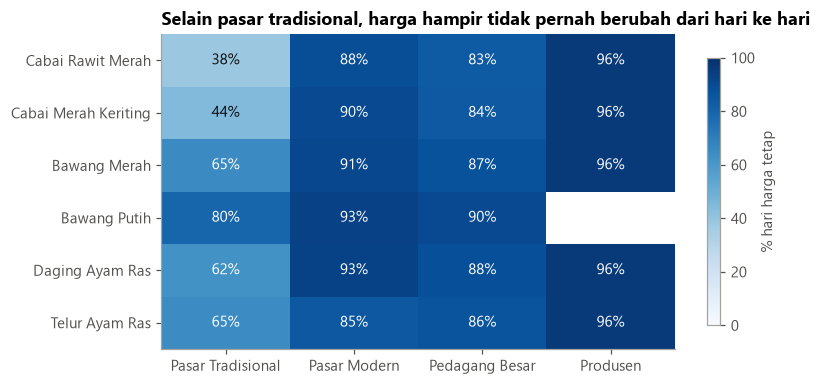

In [13]:
kota["selisih_harian"] = kota.groupby(SERI, observed=True).harga.diff()
v = kota.dropna(subset=["selisih_harian"])
datar = v.pivot_table(index="komoditas", columns="jenis_pasar", values="selisih_harian",
                      aggfunc=lambda s: (s == 0).mean() * 100, observed=True)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(datar.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(datar.shape[1]), datar.columns); ax.set_yticks(range(datar.shape[0]), datar.index)
ax.grid(False)
for i in range(datar.shape[0]):
    for j in range(datar.shape[1]):
        val = datar.iat[i, j]
        if pd.notna(val):
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", color="white" if val > 60 else INK)
ax.set_title("Selain pasar tradisional, harga hampir tidak pernah berubah dari hari ke hari")
fig.colorbar(im, ax=ax, label="% hari harga tetap", shrink=0.85)
plt.tight_layout(); plt.show()

In [14]:
def run_terpanjang(s: pd.Series) -> int:
    nol = (s == 0).to_numpy().astype(int)
    padded = np.concatenate([[0], nol, [0]]); d = np.diff(padded)
    r = np.flatnonzero(d == -1) - np.flatnonzero(d == 1)
    return int(r.max()) if len(r) else 0

run = v.groupby(SERI, observed=True).selisih_harian.apply(run_terpanjang).rename("run_datar_maks")
tabel = pd.DataFrame({f">= {t} hari": (run >= t).groupby(level="jenis_pasar", observed=True).sum()
                      for t in (40, C["usang_run_hari"], 120)})
display(tabel.rename_axis("jumlah seri dengan harga tetap berturut-turut"))
run.sort_values(ascending=False).head(8).to_frame()

,>= 40 hari,>= 60 hari,>= 120 hari
jumlah seri dengan harga tetap berturut-turut,,,
Pasar Tradisional,31,16,1
Pasar Modern,100,59,14
Pedagang Besar,39,13,3
Produsen,131,49,2


run_datar_maks
jenis_pasar    komoditas       nama                           
Pasar Modern   Daging Ayam Ras Kota Malang                 272
               Bawang Putih    Kota Bekasi                 260
Pedagang Besar Bawang Putih    Kota Bogor                  244
Produsen       Daging Ayam Ras Kab. Bojonegoro             217
Pedagang Besar Bawang Putih    Kota Bekasi                 209
Pasar Modern   Daging Ayam Ras Kota Yogyakarta             207
               Bawang Putih    Kota Yogyakarta             203
                               Kota Bogor                  203

> **Temuan:** Hanya **pasar tradisional** yang harganya cukup sering bergerak (38–80% hari tidak berubah). Produsen
> ~96%, pasar modern 85–93%, pedagang besar 83–90%; ada seri yang harganya sama selama lebih dari setahun.
> Artinya, gejolak harga dan kota penentu arah hanya bisa dianalisis dari pasar tradisional. Perbandingan gejolak
> pasar tradisional vs modern harus diberi catatan: pasar modern terlihat stabil karena datanya jarang diperbarui.
> Pedagang besar dan produsen tetap dipakai untuk **level** harga (selisih antar kota, tambahan harga), dengan tanda
> "usang" bila harganya tidak berubah ≥ 60 hari kerja.

## 5. Salah input dan lonjakan

Brief mengusulkan aturan |x − median bergulir| > 5×MAD. Di data ini aturan tersebut bermasalah: banyak seri datar
sehingga MAD ≈ 0, dan perubahan kecil pun ikut ditandai. Di bawah, aturan brief dibandingkan dengan tiga aturan
alternatif (ambang dari `config.yaml`). Aturan dibagi dua tingkat, karena lonjakan tajam pada cabai sering **nyata**:

| Aturan | Tingkat | Menangkap | Definisi |
|---|---|---|---|
| **A. Lonjakan tajam** | penanda saja (nilai tetap dipakai) | lonjakan sehari | deviasi dari median bergulir > max(5×MAD, 25%), sementara hari sebelum **dan** sesudahnya normal |
| **B. Rasio ekstrem** | salah input (dikosongkan) | kelebihan/kekurangan satu nol | harga ≥ 3× atau ≤ ⅓ median bergulir seri itu sendiri |
| **C. Lintas kota** | salah input (dikosongkan) | pergeseran level yang bertahan | harga ≥ 5× atau ≤ ⅕ median kota lain (komoditas, jenis pasar & hari sama) |

Ambang C sengaja longgar (5×): pada ambang 3×, harga produsen cabai yang memang anjlok saat panen raya di beberapa
kabupaten ikut tertangkap, padahal itu bukan salah input.

In [15]:
o = C["outlier"]
g = kota.groupby(SERI, observed=True).harga
kota["med"] = g.transform(lambda s: s.rolling(o["jendela_median_hari"], center=True, min_periods=5).median())
kota["dev"] = (kota.harga - kota.med).abs()
kota["mad"] = kota.groupby(SERI, observed=True).dev.transform(
    lambda s: s.rolling(o["jendela_median_hari"], center=True, min_periods=5).median())
batas = np.maximum(o["k_mad"] * kota.mad, o["lonjakan_deviasi_min"] * kota.med)
kota["menyimpang"] = (kota.dev > batas).where(kota.harga.notna())
gs = kota.groupby(SERI, observed=True).menyimpang
kota["aturan_brief"] = kota.dev > o["k_mad"] * kota.mad.replace(0, np.nan)
# A: hari sebelum & sesudah harus ADA dan normal (tepi data / tetangga kosong tidak dihitung)
kota["A_lonjakan_tajam"] = kota.menyimpang.eq(True) & gs.shift(1).eq(False) & gs.shift(-1).eq(False)
r = kota.harga / kota.med
kota["B_rasio_ekstrem"] = (r >= o["rasio_ekstrem"]) | (r <= 1 / o["rasio_ekstrem"])
med_lintas = kota.groupby(["jenis_pasar", "komoditas", "tanggal"], observed=True).harga.transform("median")
rl = kota.harga / med_lintas
kota["C_lintas_kota"] = (rl >= o["rasio_lintas_kota"]) | (rl <= 1 / o["rasio_lintas_kota"])
kota["salah_input"] = kota.B_rasio_ekstrem | kota.C_lintas_kota
kota["lonjakan_saja"] = kota.A_lonjakan_tajam & ~kota.salah_input

n = kota.harga.notna().sum()
ringkas = kota[["aturan_brief", "A_lonjakan_tajam", "B_rasio_ekstrem", "C_lintas_kota",
                "salah_input", "lonjakan_saja"]].sum()
pd.DataFrame({"titik ditandai": ringkas, "% dari harga terisi": (ringkas / n * 100).round(3)}).rename(index={
    "aturan_brief": "aturan brief (5×MAD)", "salah_input": "→ salah input (B atau C): dikosongkan",
    "lonjakan_saja": "→ lonjakan tajam saja (A, bukan B/C): penanda"})

,titik ditandai,% dari harga terisi
aturan brief (5×MAD),7766,1.465
A_lonjakan_tajam,117,0.022
B_rasio_ekstrem,4,0.001
C_lintas_kota,23,0.004
→ salah input (B atau C): dikosongkan,27,0.005
"→ lonjakan tajam saja (A, bukan B/C): penanda",113,0.021


In [16]:
kolom = ["jenis_pasar", "komoditas", "nama", "tanggal", "harga", "med"]
print("Salah input - aturan B (rasio ekstrem):")
display(kota[kota.B_rasio_ekstrem][kolom].sort_values("tanggal"))
print("Salah input - aturan C (lintas kota), diringkas per seri:")
display(kota[kota.C_lintas_kota].groupby(["jenis_pasar", "komoditas", "nama"], observed=True).agg(
    hari=("tanggal", "size"), mulai=("tanggal", "min"), selesai=("tanggal", "max"), harga_median=("harga", "median")))
print("Lonjakan tajam (A) per jenis pasar & komoditas - penanda saja:")
kota[kota.lonjakan_saja].pivot_table(index="komoditas", columns="jenis_pasar", values="harga", aggfunc="size",
                                     observed=True, fill_value=0)

Salah input - aturan B (rasio ekstrem):


,jenis_pasar,komoditas,nama,tanggal,harga,med
11374,Pasar Tradisional,Cabai Rawit Merah,Kab. Wonogiri,2023-12-29,232500.0,73750.0
472,Pasar Tradisional,Cabai Rawit Merah,Kab. Banyumas,2025-04-23,258750.0,78750.0
24860,Pasar Tradisional,Cabai Rawit Merah,Kota Sukabumi,2025-12-15,264250.0,78750.0
70209,Pasar Tradisional,Bawang Merah,Kab. Wonogiri,2026-05-20,143750.0,46750.0


Salah input - aturan C (lintas kota), diringkas per seri:


,,,hari,mulai,selesai,harga_median
jenis_pasar,komoditas,nama,,,,
Produsen,Bawang Merah,Kab. Garut,23,2025-03-25,2025-04-24,3000.0


Lonjakan tajam (A) per jenis pasar & komoditas - penanda saja:


jenis_pasar,Pasar Tradisional,Pasar Modern,Pedagang Besar
komoditas,,,
Cabai Rawit Merah,56,3,1
Cabai Merah Keriting,39,5,2
Bawang Merah,3,0,0
Bawang Putih,1,0,0
Daging Ayam Ras,0,1,0
Telur Ayam Ras,2,0,0


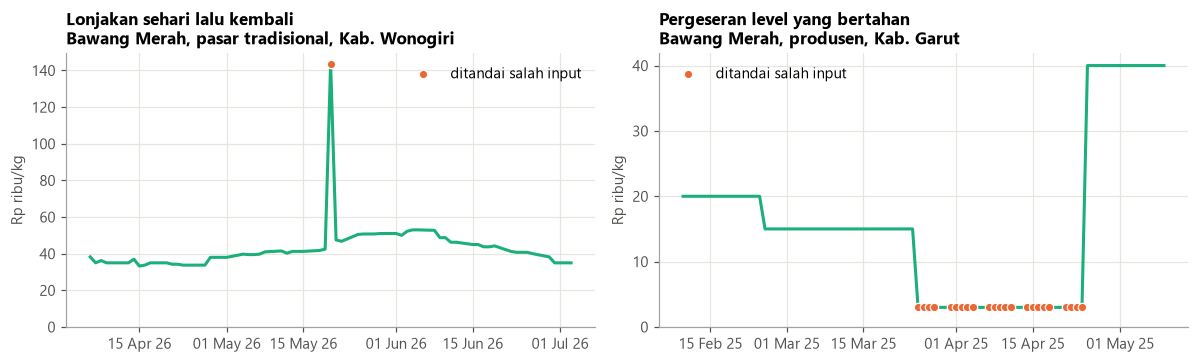

In [17]:
contoh = [("Pasar Tradisional", "Bawang Merah", "Kab. Wonogiri", "2026-05-20", "Lonjakan sehari lalu kembali"),
          ("Produsen", "Bawang Merah", "Kab. Garut", "2025-03-25", "Pergeseran level yang bertahan")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, (ps, km, nm, t0, judul) in zip(axes, contoh):
    t0 = pd.Timestamp(t0)
    s = kota[(kota.jenis_pasar == ps) & (kota.komoditas == km) & (kota.nama == nm)
             & kota.tanggal.between(t0 - pd.Timedelta(days=45), t0 + pd.Timedelta(days=45))]
    ax.plot(s.tanggal, s.harga / 1000, color=TEAL, lw=2)
    f = s[s.salah_input]
    ax.scatter(f.tanggal, f.harga / 1000, color=ORANGE, s=30, zorder=3, edgecolor="white", lw=0.8,
               label="ditandai salah input")
    ax.set_title(f"{judul}\n{km}, {ps.lower()}, {nm}", fontsize=11)
    ax.set_ylabel("Rp ribu/kg"); ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %y")); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Lonjakan regional yang kemungkinan nyata.** Pada 20 Juni 2025, cabai merah keriting di beberapa kota Banten naik
hampir dua kali lipat lalu turun bertahap selama beberapa hari. Karena terjadi serentak di beberapa kota, ini lebih
mungkin kejadian pasar daripada salah ketik. Aturan A menandainya sebagai lonjakan tajam, tetapi nilainya tetap
dipakai; aturan B dan C tidak menganggapnya salah input.

In [18]:
banten = trad[(trad.komoditas == "Cabai Merah Keriting") & (trad.provinsi == "Banten")
              & trad.tanggal.between("2025-06-16", "2025-06-27")]
banten.pivot_table(index="nama", columns=banten.tanggal.dt.strftime("%d %b"), values="harga", observed=True,
                   sort=False).reindex(columns=banten.tanggal.dt.strftime("%d %b").unique())

tanggal,16 Jun,17 Jun,18 Jun,19 Jun,20 Jun,23 Jun,24 Jun,25 Jun,26 Jun,27 Jun
nama,,,,,,,,,,
Kota Cilegon,37000.0,35000.0,35000.0,38000.0,74750.0,47250.0,35750.0,34500.0,33500.0,33500.0
Kota Serang,37750.0,36000.0,36000.0,37750.0,72250.0,42750.0,41250.0,34000.0,34000.0,34000.0
Kota Tangerang,35250.0,33250.0,33250.0,45000.0,67500.0,47750.0,42000.0,42500.0,38000.0,38000.0


> **Temuan:** Salah input jarang, tetapi nyata. Contohnya bawang merah Rp 143.750/kg di Wonogiri selama sehari,
> dan harga produsen bawang merah di Garut yang turun ke Rp 3.000/kg lalu bertahan sebulan. Aturan di brief menandai
> lebih dari 7 ribu titik yang sebagian besar normal. Aturan usulan hanya mengosongkan 27 titik yang jelas salah input,
> dan memberi penanda pada lonjakan tajam lain tanpa membuangnya, karena lonjakan cabai sering memang terjadi.

## 6. Kewajaran level harga

Untuk analisis tambahan harga (Q5), urutan harga harus masuk akal: produsen < pedagang besar < pasar tradisional.

In [19]:
lvl = kota.pivot_table(index="komoditas", columns="jenis_pasar", values="harga", aggfunc="median", observed=True)
lvl["urutan wajar"] = (lvl["Produsen"].isna() | (lvl["Produsen"] < lvl["Pedagang Besar"])) & \
                      (lvl["Pedagang Besar"] < lvl["Pasar Tradisional"])
lvl.style.format({c: "Rp {:,.0f}" for c in PASAR}, na_rep="–").set_caption("Median harga (Rp/kg)")

jenis_pasar,Pasar Tradisional,Pasar Modern,Pedagang Besar,Produsen,urutan wajar
komoditas,,,,,
Cabai Rawit Merah,"Rp 51,250","Rp 90,250","Rp 42,000","Rp 33,000",True
Cabai Merah Keriting,"Rp 43,600","Rp 79,900","Rp 35,000","Rp 25,500",True
Bawang Merah,"Rp 37,750","Rp 57,450","Rp 29,500","Rp 22,000",True
Bawang Putih,"Rp 38,500","Rp 52,450","Rp 32,500",–,True
Daging Ayam Ras,"Rp 36,000","Rp 44,400","Rp 32,500","Rp 28,500",True
Telur Ayam Ras,"Rp 27,250","Rp 27,750","Rp 25,500","Rp 24,500",True


> **Temuan:** Urutan harga wajar untuk semua komoditas: produsen termurah, lalu pedagang besar, pasar tradisional,
> dan pasar modern termahal. Pasar modern bisa hampir dua kali harga pasar tradisional untuk cabai.

## 7. Kecocokan data dengan tujuan analisis

### Kota tujuan & sumber (Q2)
Untuk rute pindah stok, kota sumber memakai harga **pedagang besar** (lebih realistis untuk pembelian distributor),
kota tujuan memakai harga **pasar tradisional**. Angka = jumlah hari terisi dari total hari kerja.

In [20]:
w = cfg["wilayah"]
terisi_hari = kota[kota.harga.notna()].groupby(["jenis_pasar", "komoditas", "nama"], observed=True).size()
baris = []
for nama in w["kota_tujuan"].values():
    for km in KOMODITAS.values():
        baris.append(("tujuan", nama, km, terisi_hari.get(("Pasar Tradisional", km, nama), 0),
                      terisi_hari.get(("Pedagang Besar", km, nama), 0)))
for v_ in w["kota_sumber"].values():
    for cid in v_["komoditas"]:
        km = KOMODITAS[cid]
        baris.append(("sumber", v_["nama"], km, terisi_hari.get(("Pasar Tradisional", km, v_["nama"]), 0),
                      terisi_hari.get(("Pedagang Besar", km, v_["nama"]), 0)))
cakupan = pd.DataFrame(baris, columns=["peran", "kota", "komoditas", "hari_tradisional", "hari_pedagang_besar"])
print(f"Total hari kerja: {len(tgl)} | hari terisi minimum: {cakupan[['hari_tradisional', 'hari_pedagang_besar']].min().min()}")
cakupan[cakupan.peran == "sumber"]

Total hari kerja: 865 | hari terisi minimum: 836


,peran,kota,komoditas,hari_tradisional,hari_pedagang_besar
24,sumber,Kota Tasikmalaya,Cabai Merah Keriting,861,865
25,sumber,Kota Tegal,Bawang Merah,861,865
26,sumber,Kota Kediri,Cabai Rawit Merah,865,865
27,sumber,Kota Kediri,Telur Ayam Ras,865,865
28,sumber,Kota Kediri,Daging Ayam Ras,865,865
29,sumber,Kab. Jember,Cabai Rawit Merah,852,861
30,sumber,Kab. Banyuwangi,Cabai Rawit Merah,851,861
31,sumber,Kota Probolinggo,Bawang Merah,862,865


### Tiga tingkat harga di kota yang sama (Q5)
Brief: "analisis hanya kota yang lengkap". Produsen dicatat di kabupaten sentra, sehingga nama kotanya sering berbeda
dari kota pasar tradisional.

In [21]:
nama_per = kota.groupby(["komoditas", "jenis_pasar"], observed=True).nama.apply(set)
lengkap = {km: sorted(nama_per.get((km, "Produsen"), set()) & nama_per.get((km, "Pedagang Besar"), set())
                      & nama_per.get((km, "Pasar Tradisional"), set())) for km in KOMODITAS.values()}
pd.DataFrame({"jumlah kota lengkap 3 tingkat": {k: len(v) for k, v in lengkap.items()},
              "kota": {k: ", ".join(v) for k, v in lengkap.items()}})

,jumlah kota lengkap 3 tingkat,kota
Cabai Rawit Merah,7,"Kab. Banyumas, Kab. Jember, Kota Malang, Kota ..."
Cabai Merah Keriting,6,"Kab. Banyumas, Kota Malang, Kota Semarang, Kot..."
Bawang Merah,6,"Kab. Cilacap, Kab. Jember, Kota Semarang, Kota..."
Bawang Putih,0,
Daging Ayam Ras,11,"Kab. Banyumas, Kab. Cilacap, Kab. Jember, Kota..."
Telur Ayam Ras,7,"Kab. Banyumas, Kab. Cilacap, Kab. Jember, Kota..."


### Data mingguan (Q3, Q4, Q6)
Analisis kota penentu arah, pola Idul Fitri, dan peringatan dini memakai median mingguan (minggu berakhir Jumat).
Hitungan di bawah **sudah mengeluarkan hari libur** (§2), karena harga hari libur bukan hasil pencacahan.

In [22]:
nyata = trad[trad.harga.notna() & ~trad.tanggal.isin(libur.index)].copy()
nyata["minggu"] = nyata.tanggal.dt.to_period("W-FRI")
hari_per_minggu = nyata.groupby(SERI + ["minggu"], observed=True).size()
semua_minggu = pd.period_range(tgl.min(), tgl.max(), freq="W-FRI")
print(f"{len(semua_minggu)} minggu | kombinasi seri-minggu pasar tradisional: {len(hari_per_minggu):,}")
tipis = (hari_per_minggu < C["minggu_min_hari_nyata"])
print(f"Minggu tipis (< {C['minggu_min_hari_nyata']} hari nyata): {tipis.sum():,} ({tipis.mean():.1%})")
hari_per_minggu.value_counts().sort_index().rename("jumlah seri-minggu").rename_axis("hari nyata per minggu").to_frame().T

173 minggu | kombinasi seri-minggu pasar tradisional: 35,445
Minggu tipis (< 3 hari nyata): 427 (1.2%)


hari nyata per minggu,1,2,3,4,5
jumlah seri-minggu,1,426,2935,6112,25971


In [23]:
# Minggu tanpa satu pun hari pencacahan nyata (seluruh minggu libur)
minggu_kosong = semua_minggu.difference(nyata.minggu.unique())
print("Minggu tanpa pencacahan nyata sama sekali:", [str(m) for m in minggu_kosong])

Minggu tanpa pencacahan nyata sama sekali: ['2024-04-06/2024-04-12', '2025-03-29/2025-04-04']


| Pertanyaan | Kecukupan data | Catatan |
|---|---|---|
| Q1 Gejolak | ✅ cukup | pasar tradisional, 35 kota |
| Q2 Rute untung | ✅ lengkap | 10 kota usulan terisi hampir setiap hari kerja |
| Q3 Kota penentu arah | ✅ cukup | 173 minggu, 35 kota |
| Q4 Pola Idul Fitri | ⚠️ terbatas | hanya 3 Idul Fitri; minggu Lebaran sebagian/seluruhnya tanpa pencacahan |
| Q5 Tambahan harga | ⚠️ terbatas | 6–11 kota lengkap per komoditas; bawang putih tidak ada |
| Q6 Peringatan dini | ⚠️ terbatas | uji pada data baru hanya untuk 2025 dan 2026 |

> **Temuan:** Data siap untuk pertanyaan gejolak, rute, dan kota penentu arah. Untuk pola Lebaran, peringatan dini,
> dan tambahan harga, hasilnya harus dibaca sebagai perkiraan kasar dan batasannya ditulis jelas.

## 8. Rekomendasi preprocessing

### Empat keputusan utama
| # | Keputusan | Alasan (bagian) |
|---|---|---|
| 1 | **Surakarta pasar modern:** pakai id 36 "Kota Surakarta (Solo)", buang id 787 "Kota Surakarta" | duplikat, nilai identik 87% hari (§1) |
| 2 | **Hari libur yang diisi harga sebelumnya** ditandai `is_libur_isi` dan dianggap kosong untuk perhitungan harian & mingguan | bukan hasil pencacahan (§2) |
| 3 | **Outlier dua tingkat** menggantikan aturan 5×MAD murni. *Salah input* (B rasio ekstrem ≥ 3×, C lintas kota ≥ 5×) → `is_outlier_flag` + alasan, nilai dikosongkan di versi bersih. *Lonjakan tajam* (A) → `is_lonjakan_tajam`, nilai tetap dipakai. Nilai asli selalu disimpan | aturan brief menandai > 7 ribu titik yang sebagian besar normal; lonjakan cabai sering nyata (§5) |
| 4 | **Tambahan harga (Q5):** analisis utama hanya kota yang lengkap 3 tingkat dengan nama sama (sesuai brief); analisis tambahan memasangkan kota dengan kabupaten sentra di sekitarnya (mis. Kota Kediri ↔ Kab. Kediri, Kota Probolinggo ↔ Kab. Probolinggo, Kota Tasikmalaya ↔ Kab. Garut), berlabel `PERLU_VERIFIKASI` | cakupan kota lengkap sedikit (§7) |

### Urutan langkah cleaning (Tahap 2, `src/clean.py`)
1. Parse JSON → format panjang (`src/load_raw.py`). Baris nasional disimpan terpisah sebagai pembanding; baris provinsi dibuang.
2. Standarisasi kota: `strip()`, petakan nama → id via referensi, buang id 787.
3. Tandai hari libur (`is_libur_isi`) → kosong.
4. Tandai salah input (aturan B/C) → kosong pada versi bersih; tandai lonjakan tajam (aturan A) tanpa mengubah nilai.
   Nilai asli selalu disimpan.
5. Isi celah ≤ 5 hari kerja (forward-fill, `is_imputed`); celah lebih panjang tetap kosong.
6. Tandai data usang (`is_usang`: harga tetap ≥ 60 hari kerja).
7. Tabel kualitas data per kota × komoditas × jenis pasar.
8. Tes: harga > 0, tidak ada duplikat kunci, tanggal hanya hari kerja, setiap kota punya id.

### Implikasi untuk analisis
- Gejolak (Q1) dan kota penentu arah (Q3): **hanya pasar tradisional**.
- Selisih antar kota (Q2) dan tambahan harga (Q5): pedagang besar & produsen dipakai untuk level harga, bertanda usang bila perlu.
- Pola Idul Fitri (Q4): minggu Lebaran tanpa pencacahan ditandai `minggu_tipis`, bukan dianggap "harga stabil".